In [1]:
from datasets import load_from_disk

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
dataset = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_0.01_sample_32_None_None_None_None_None_shifted_log_knn_10_ordered.dataset')

In [2]:
dataset = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10.dataset')

In [10]:
dataset = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_0.01_sample_32_None_None_None_None_None_shifted_log_knn_10_ordered_fixed.dataset')

In [16]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 813606
})

In [17]:
dataset['n_nonzero_tokens'][-100:]

[126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 122,
 122,
 122,
 122,
 122,
 122,
 122,
 122,
 122,
 121,
 121,
 121,
 121,
 121,
 121,
 120,
 120,
 120,
 120,
 120,
 120,
 120,
 119,
 119,
 119,
 119,
 119,
 119,
 119,
 118,
 118,
 118,
 117,
 117,
 116,
 116,
 115,
 114]

In [4]:
rel_x_coord = dataset['rel_x_coord']

In [9]:
len(rel_x_coord[0])

11

In [8]:
dataset2 = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_fixed.dataset')

In [13]:
train_mode = True

def set_minimal_format(d):
    cols = [c for c in d.column_names if c != 'cell_id' or not train_mode]
    d.set_format(type="torch", columns=cols, output_all_columns=False)
    return d

dataset2 = set_minimal_format(dataset2)

In [14]:
dataset2

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 88626282
})

In [15]:
item = dataset2[0]

In [16]:
item

{'rel_x_coord': tensor([  0.0000,  -7.3698,   3.2038,   8.8273,   1.9876,  -8.0532,  -7.2925,
           6.5730, -14.7948,  -2.1206,  15.0741]),
 'rel_y_coord': tensor([ 0.0000,  1.6421, -7.1665,  1.1333,  9.9331, -8.2656, 11.0161, 15.4580,
         -8.0322, 17.5508,  9.5073]),
 'batch_value': tensor([166]),
 'gene_panel_value': tensor([127]),
 'assay_value': tensor([122]),
 'species_value': tensor([102]),
 'tissue_value': tensor([103]),
 'gene_tokens': tensor([ 1415, 10413,  3295,  ...,     0,     0,     0]),
 'gene_expr': tensor([2.8332, 2.7081, 2.5649,  ..., 0.0000, 0.0000, 0.0000]),
 'n_nonzero_tokens': tensor(910)}

In [18]:
'seg_tokens' in item.keys()

False

In [5]:
nz_tokens = list(dataset['n_nonzero_tokens'])

In [7]:
nz_tokens[-100:]

[126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 126,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 125,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 124,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 123,
 122,
 122,
 122,
 122,
 122,
 122,
 122,
 122,
 122,
 121,
 121,
 121,
 121,
 121,
 121,
 120,
 120,
 120,
 120,
 120,
 120,
 120,
 119,
 119,
 119,
 119,
 119,
 119,
 119,
 118,
 118,
 118,
 117,
 117,
 116,
 116,
 115,
 114]

In [70]:
test_batch_ids = ['49_batch0',
                                 '59_batch0',
                                 '59_batch3',
                                 '59_batch6',
                                 '59_batch7',
                                 '59_batch2',
                                 '59_batch4',
                                 '59_batch1',
                                 '59_batch5',
                                 '78_batch3',
                                 '78_batch10',
                                 '78_batch1',
                                 '78_batch0',
                                 '78_batch2',
                                 '78_batch6',
                                 '78_batch7',
                                 '78_batch9',
                                 '78_batch8',
                                 '78_batch4',
                                 '78_batch5',
                                 '1000_batch4',
                                 '1000_batch6',
                                 '1000_batch11',
                                 '1000_batch12',
                                 '1000_batch18',
                                 '1000_batch19',
                                 '1000_batch21',
                                 '1000_batch22',
                                 '1000_batch34',
                                 '1000_batch38',
                                 '1000_batch20',
                                 '1000_batch26',
                                 '1000_batch27',
                                 '1000_batch32',
                                 '1000_batch36',
                                 '1002_batch3',
                                 '1002_batch15'
                                 '1002_batch27',
                                 '1002_batch39',
                                 '1002_batch45',
                                 '1002_batch26',
                                 '1002_batch4',
                                 '1002_batch16'
                                 '1002_batch18',
                                 '1002_batch23',
                                 '1002_batch31',
                                 '1002_batch34',
                                 '1002_batch53',
                                 '1002_batch55',
                                 '1002_batch40',
                                 '1002_batch46',
                                 '1007_batch1',
                                 '1007_batch14',
                                 '1007_batch20',
                                 '1007_batch36',
                                 '1007_batch17',
                                 '1007_batch33',
                                 '1007_batch4',
                                 '1007_batch2',
                                 '1007_batch0',
                                 '1007_batch27',
                                 '1007_batch3',
                                 '1007_batch12',
                                 '1007_batch19',
                                 '1007_batch24',
                                 '1007_batch6',
                                 '1007_batch25',
                                 '1007_batch34',
                                 '1007_batch30',
                                 '1007_batch39',
                                 '1007_batch22',
                                 '1009_batch0',
                                 '1009_batch1',
                                 '1009_batch2',
                                 '1009_batch3',
                                 '1009_batch4',
                                 '1009_batch5',
                                 '1009_batch6',
                                 '1009_batch7',
                                 '1009_batch8',
                                 '1009_batch9',
                                 '1009_batch10',
                                 '1009_batch11',
                                 '1009_batch12',
                                 '1009_batch13',
                                 '1009_batch14',
                                 '1009_batch15',
                                 '1009_batch16',
                                 '1011_batch0',
                                 '1011_batch1',
                                 '1011_batch2',
                                 '1011_batch3',
                                 '1011_batch4',
                                 '1011_batch5',
                                 '1011_batch6',
                                 '1011_batch7',
                                 '1011_batch8',
                                 '1011_batch9',
                                 '1011_batch10',
                                 '1011_batch11',
                                 '1011_batch12',
                                 '1011_batch13',
                                 '1011_batch14',
                                 '1011_batch15',
                                 '1011_batch16',
                                 '1011_batch17',
                                 '1011_batch18',
                                 '1011_batch19',
                                 '1011_batch20',
                                 '1011_batch21']

In [71]:
test_batch_ids

['49_batch0',
 '59_batch0',
 '59_batch3',
 '59_batch6',
 '59_batch7',
 '59_batch2',
 '59_batch4',
 '59_batch1',
 '59_batch5',
 '78_batch3',
 '78_batch10',
 '78_batch1',
 '78_batch0',
 '78_batch2',
 '78_batch6',
 '78_batch7',
 '78_batch9',
 '78_batch8',
 '78_batch4',
 '78_batch5',
 '1000_batch4',
 '1000_batch6',
 '1000_batch11',
 '1000_batch12',
 '1000_batch18',
 '1000_batch19',
 '1000_batch21',
 '1000_batch22',
 '1000_batch34',
 '1000_batch38',
 '1000_batch20',
 '1000_batch26',
 '1000_batch27',
 '1000_batch32',
 '1000_batch36',
 '1002_batch3',
 '1002_batch151002_batch27',
 '1002_batch39',
 '1002_batch45',
 '1002_batch26',
 '1002_batch4',
 '1002_batch161002_batch18',
 '1002_batch23',
 '1002_batch31',
 '1002_batch34',
 '1002_batch53',
 '1002_batch55',
 '1002_batch40',
 '1002_batch46',
 '1007_batch1',
 '1007_batch14',
 '1007_batch20',
 '1007_batch36',
 '1007_batch17',
 '1007_batch33',
 '1007_batch4',
 '1007_batch2',
 '1007_batch0',
 '1007_batch27',
 '1007_batch3',
 '1007_batch12',
 '1007_

In [44]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import copy
import pickle

import numpy as np
import torch
from datasets import load_from_disk

from nichejepa.datasets.cell_neighborhood_dataset import make_cell_neighborhood_dataset 
from nichejepa.helper import init_model
from nichejepa.masks.multigene import MaskCollator
from nichejepa.utils.distributed import init_distributed

from logging import getLogger
from multiprocessing import Value

import torch.nn.functional as F

from nichejepa.masks.utils import apply_masks
from nichejepa.utils.tensors import repeat_interleave_batch

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


ModuleNotFoundError: No module named 'nichejepa.datasets.cell_neighborhood_dataset'

In [ ]:
def get_1d_sincos_pos_embed_from_grid(embed_dim, pos):
    """
    embed_dim: output dimension for each position
    pos: a list of positions to be encoded: size (M,)
    out: (M, D)
    """
    assert embed_dim % 2 == 0
    omega = np.arange(embed_dim // 2, dtype=float)
    omega /= embed_dim / 2.
    omega = 1. / 10000**omega   # (D/2,)

    pos = pos.reshape(-1)   # (M,)
    out = np.einsum('m,d->md', pos, omega)   # (M, D/2), outer product

    emb_sin = np.sin(out)  # (M, D/2)
    emb_cos = np.cos(out)  # (M, D/2)

    emb = np.concatenate([emb_sin, emb_cos], axis=1)  # (M, D)
    return emb

In [ ]:
def get_1d_sincos_pos_embed(embed_dim, grid_size, cls_token=False):
    """
    grid_size: int of the grid length
    return:
    pos_embed: [grid_size, embed_dim] or [1+grid_size, embed_dim] (w/ or w/o cls_token)
    """
    grid = np.arange(grid_size, dtype=float)
    pos_embed = get_1d_sincos_pos_embed_from_grid(embed_dim, grid)
    if cls_token:
        pos_embed = np.concatenate([np.zeros([1, embed_dim]), pos_embed], axis=0)
    return pos_embed

In [ ]:
pos_embed = get_1d_sincos_pos_embed(embed_dim=4, grid_size=10, cls_token=False)

In [ ]:
pos_embed

In [ ]:
def get_2d_sincos_pos_embed_from_grid(embed_dim, grid):
    assert embed_dim % 2 == 0

    # use half of dimensions to encode grid_h
    emb_h = get_1d_sincos_pos_embed_from_grid(embed_dim // 2, grid[0])  # (H*W, D/2)
    emb_w = get_1d_sincos_pos_embed_from_grid(embed_dim // 2, grid[1])  # (H*W, D/2)

    emb = np.concatenate([emb_h, emb_w], axis=1)  # (H*W, D)
    return emb

In [ ]:
def get_2d_sincos_pos_embed(embed_dim, grid_size, cls_token=False):
    """
    grid_size: int of the grid height and width
    return:
    pos_embed: [grid_size*grid_size, embed_dim] or [1+grid_size*grid_size, embed_dim] (w/ or w/o cls_token)
    """
    grid_h = np.arange(grid_size, dtype=float)
    grid_w = np.arange(grid_size, dtype=float)
    grid = np.meshgrid(grid_w, grid_h)  # here w goes first
    grid = np.stack(grid, axis=0)

    grid = grid.reshape([2, 1, grid_size, grid_size])
    pos_embed = get_2d_sincos_pos_embed_from_grid(embed_dim, grid)
    if cls_token:
        pos_embed = np.concatenate([np.zeros([1, embed_dim]), pos_embed], axis=0)
    return pos_embed

In [ ]:
pos_embed = get_2d_sincos_pos_embed(embed_dim=4, grid_size=10, cls_token=False)

In [ ]:
pos_embed.shape

In [ ]:
grid_size = 10

grid_h = np.arange(grid_size, dtype=float)
grid_w = np.arange(grid_size, dtype=float)
grid = np.meshgrid(grid_w, grid_h)  # here w goes first

In [ ]:
grid = np.stack(grid, axis=0)

In [ ]:
grid

In [ ]:
grid = grid.reshape([2, 1, grid_size, grid_size])

In [ ]:
grid

In [ ]:
x = torch.tensor([[2, 3, 5], [6,7,8]])

In [18]:
shape = (x.shape[0],) + (1,) * (x.ndim - 1) 

In [19]:
shape

(2, 1)

In [20]:
x.shape[0]

2

In [21]:
(x.shape[0],) + (1,)

(2, 1)

In [22]:
(1,) * (x.ndim - 1) 

(1,)

In [23]:
None or 200

200

In [24]:
drop_path_rate = 0.5
depth = 10

dpr = [x.item() for x in torch.linspace(0, drop_path_rate, depth)]

In [25]:
dpr

[0.0,
 0.0555555559694767,
 0.1111111119389534,
 0.1666666716337204,
 0.2222222238779068,
 0.2777777910232544,
 0.3333333432674408,
 0.3888888955116272,
 0.4444444477558136,
 0.5]

In [26]:
batch = (torch.tensor([1, 2]), torch.tensor([3, 4]))

In [27]:
batch

(tensor([1, 2]), tensor([3, 4]))

In [28]:
torch.utils.data.default_collate(batch)

tensor([[1, 2],
        [3, 4]])

In [29]:
from multiprocessing import Value

In [30]:
Value('i', -1)

<Synchronized wrapper for c_int(-1)>

In [31]:
g = torch.Generator()

In [32]:
def _sample_block_size(self, generator, scale, aspect_ratio_scale):
    _rand = torch.rand(1, generator=generator).item()
    # -- Sample block scale
    min_s, max_s = scale
    mask_scale = min_s + _rand * (max_s - min_s)
    max_keep = int(self.height * self.width * mask_scale)
    # -- Sample block aspect-ratio
    min_ar, max_ar = aspect_ratio_scale
    aspect_ratio = min_ar + _rand * (max_ar - min_ar)
    # -- Compute block height and width (given scale and aspect-ratio)
    h = int(round(math.sqrt(max_keep * aspect_ratio)))
    w = int(round(math.sqrt(max_keep / aspect_ratio)))
    while h >= self.height:
        h -= 1
    while w >= self.width:
        w -= 1

    return (h, w)

In [33]:
_rand = torch.rand(1).item()

In [34]:
_rand

0.8409873843193054

In [37]:
def apply_masks(x, masks):
    """
    :param x: tensor of shape [B (batch-size), N (num-patches), D (feature-dim)]
    :param masks: list of tensors containing indices of patches in [N] to keep
    """
    all_x = []
    for m in masks:
        mask_keep = m.unsqueeze(-1).repeat(1, 1, x.size(-1))
        all_x += [torch.gather(x, dim=1, index=mask_keep)]
    return torch.cat(all_x, dim=0)

In [38]:
x = torch.tensor([
    [[1, 2, 1, 2], [3, 4, 3, 1], [5, 6, 7, 2]],  # Batch 1
    [[7, 8, 2, 1], [9, 10, 5, 3], [11, 12, 8, 4]]  # Batch 2
])
masks = [torch.tensor([0, 2])] # , torch.tensor([1])]

In [39]:
x

tensor([[[ 1,  2,  1,  2],
         [ 3,  4,  3,  1],
         [ 5,  6,  7,  2]],

        [[ 7,  8,  2,  1],
         [ 9, 10,  5,  3],
         [11, 12,  8,  4]]])

In [40]:
for m in masks:
    mask_keep = m.unsqueeze(-1).repeat(1, 1, x.size(-1))

In [41]:
mask_keep

tensor([[[0, 0, 0, 0],
         [2, 2, 2, 2]]])

In [42]:
all_x = []
all_x += [torch.gather(x, dim=1, index=mask_keep)]

In [43]:
x

tensor([[[ 1,  2,  1,  2],
         [ 3,  4,  3,  1],
         [ 5,  6,  7,  2]],

        [[ 7,  8,  2,  1],
         [ 9, 10,  5,  3],
         [11, 12,  8,  4]]])

In [44]:
mask_keep

tensor([[[0, 0, 0, 0],
         [2, 2, 2, 2]]])

In [45]:
all_x

[tensor([[[1, 2, 1, 2],
          [5, 6, 7, 2]]])]

In [46]:
torch.cat(all_x, dim=0)

tensor([[[1, 2, 1, 2],
         [5, 6, 7, 2]]])

In [47]:
batch

(tensor([1, 2]), tensor([3, 4]))

In [48]:
B = len(batch)

In [49]:
collated_batch = torch.utils.data.default_collate(batch)

In [50]:
collated_batch

tensor([[1, 2],
        [3, 4]])

In [51]:
import math

def _sample_block_size(generator, scale, aspect_ratio_scale):

    height = 224 / 16
    width = 224 / 16

    print(height)

    _rand = torch.rand(1, generator=generator).item()
    print(_rand)
    # -- Sample block scale
    min_s, max_s = scale
    mask_scale = min_s + _rand * (max_s - min_s)
    print(mask_scale)
    max_keep = int(height * width * mask_scale)
    print(max_keep)
    # -- Sample block aspect-ratio
    min_ar, max_ar = aspect_ratio_scale
    aspect_ratio = min_ar + _rand * (max_ar - min_ar)
    # -- Compute block height and width (given scale and aspect-ratio)
    h = int(round(math.sqrt(max_keep * aspect_ratio)))
    w = int(round(math.sqrt(max_keep / aspect_ratio)))
    print(h)
    print(w)
    print(aspect_ratio)
    while h >= height:
        h -= 1
    while w >= width:
        w -= 1

    return (h, w)

In [52]:
g = torch.Generator()
pred_mask_scale=(0.2, 0.8)
aspect_ratio=(0.3, 3.0)

p_size = _sample_block_size(
            generator=g,
            scale=pred_mask_scale,
            aspect_ratio_scale=aspect_ratio)

14.0
0.267295241355896
0.36037714481353766
70
8
8
1.0216971516609192


In [53]:
top = torch.randint(0, 12, (1,))

In [54]:
def _sample_block_mask(b_size, acceptable_regions=None):
    h, w = b_size

    height = int(224 / 16)
    width = int(224 / 16)
    min_keep = 4

    def constrain_mask(mask, tries=0):
        """ Helper to restrict given mask to a set of acceptable regions """
        N = max(int(len(acceptable_regions)-tries), 0)
        for k in range(N):
            mask *= acceptable_regions[k]
    # --
    # -- Loop to sample masks until we find a valid one
    tries = 0
    timeout = og_timeout = 20
    valid_mask = False
    while not valid_mask:
        # -- Sample block top-left corner
        top = torch.randint(0, height - h, (1,))
        left = torch.randint(0, width - w, (1,))
        mask = torch.zeros((height, width), dtype=torch.int32)
        mask[top:top+h, left:left+w] = 1
        # -- Constrain mask to a set of acceptable regions
        if acceptable_regions is not None:
            constrain_mask(mask, tries)
        mask = torch.nonzero(mask.flatten())
        # -- If mask too small try again
        valid_mask = len(mask) > min_keep
        if not valid_mask:
            timeout -= 1
            if timeout == 0:
                tries += 1
                timeout = og_timeout
                logger.warning(f'Mask generator says: "Valid mask not found, decreasing acceptable-regions [{tries}]"')
    mask = mask.squeeze()
    # --
    mask_complement = torch.ones((height, width), dtype=torch.int32)
    mask_complement[top:top+h, left:left+w] = 0
    # --
    return mask, mask_complement

In [55]:
mask, mask_c = _sample_block_mask(p_size, acceptable_regions=None)

In [56]:
mask

tensor([ 74,  75,  76,  77,  78,  79,  80,  81,  88,  89,  90,  91,  92,  93,
         94,  95, 102, 103, 104, 105, 106, 107, 108, 109, 116, 117, 118, 119,
        120, 121, 122, 123, 130, 131, 132, 133, 134, 135, 136, 137, 144, 145,
        146, 147, 148, 149, 150, 151, 158, 159, 160, 161, 162, 163, 164, 165,
        172, 173, 174, 175, 176, 177, 178, 179])

In [57]:
mask_c

tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

In [58]:
batch

(tensor([1, 2]), tensor([3, 4]))

In [78]:
g = torch.Generator()
pred_mask_scale=(0.15, 0.2)
aspect_ratio=(0.75, 1.5)
enc_mask_scale=(0.85, 1.0)
height = int(224/16)
width = int(224/16)
npred = 4
nenc = 1
allow_overlap = False

def call_mask(batch):
    '''
    Create encoder and predictor masks when collating imgs into a batch
    # 1. sample enc block (size + location) using seed
    # 2. sample pred block (size) using seed
    # 3. sample several enc block locations for each image (w/o seed)
    # 4. sample several pred block locations for each image (w/o seed)
    # 5. return enc mask and pred mask
    '''
    B = len(batch)
    
    collated_batch = torch.utils.data.default_collate(batch)
    
    seed = 42
    g = torch.Generator()
    g.manual_seed(seed)
    p_size = _sample_block_size(
        generator=g,
        scale=pred_mask_scale,
        aspect_ratio_scale=aspect_ratio)
    e_size = _sample_block_size(
        generator=g,
        scale=enc_mask_scale,
        aspect_ratio_scale=(1., 1.))
    
    collated_masks_pred, collated_masks_enc = [], []
    min_keep_pred = height * width
    min_keep_enc = height * width
    for _ in range(B):
    
        masks_p, masks_C = [], []
        for _ in range(npred):
            mask, mask_C = _sample_block_mask(p_size)
            masks_p.append(mask)
            masks_C.append(mask_C)
            min_keep_pred = min(min_keep_pred, len(mask))
        collated_masks_pred.append(masks_p)
    
        acceptable_regions = masks_C
        try:
            if allow_overlap:
                acceptable_regions= None
        except Exception as e:
            logger.warning(f'Encountered exception in mask-generator {e}')
    
        masks_e = []
        for _ in range(nenc):
            mask, _ = _sample_block_mask(e_size, acceptable_regions=acceptable_regions)
            masks_e.append(mask)
            min_keep_enc = min(min_keep_enc, len(mask))
        collated_masks_enc.append(masks_e)

    print(collated_masks_enc[0][0].shape)
    print(collated_masks_enc[1][0].shape)
    
    collated_masks_pred = [[cm[:min_keep_pred] for cm in cm_list] for cm_list in collated_masks_pred]
    collated_masks_pred = torch.utils.data.default_collate(collated_masks_pred)
    # --
    collated_masks_enc = [[cm[:min_keep_enc] for cm in cm_list] for cm_list in collated_masks_enc]
    collated_masks_enc = torch.utils.data.default_collate(collated_masks_enc)

    print(collated_masks_enc[0].shape)
    
    return collated_batch, collated_masks_enc, collated_masks_pred

In [79]:
batch = [torch.randint(255, (224, 224)), torch.randint(255, (224, 224))]

collated_batch, collated_masks_enc, collated_masks_pred = call_mask(batch)

14.0
0.8822692632675171
0.19411346316337585
38
7
5
1.4117019474506378
14.0
0.9150039553642273
0.987250593304634
193
14
14
1.0
torch.Size([69])
torch.Size([86])
torch.Size([2, 69])


In [81]:
collated_batch

tensor([[[ 54, 199, 128,  ..., 245, 197, 221],
         [ 13, 158,  63,  ..., 100, 108,  59],
         [138, 211,  47,  ..., 153, 199, 222],
         ...,
         [ 59,  57, 190,  ...,  16, 151, 161],
         [ 64, 130,  97,  ..., 252,  84,   2],
         [ 39, 169, 127,  ..., 124, 180,  37]],

        [[  6,  80, 185,  ...,  64,  75, 155],
         [ 35, 223,   4,  ..., 194,  26,  48],
         [ 54,  35, 181,  ..., 242, 243, 253],
         ...,
         [ 89, 246, 176,  ..., 166, 167, 148],
         [154,  18, 130,  ..., 199, 107, 155],
         [ 79, 137,  51,  ...,  68, 231,  52]]])

In [82]:
collated_masks_enc

[tensor([[  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  14,
           15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  28,  29,
           30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  42,  43,  44,
           45,  46,  47,  53,  54,  56,  67,  68,  70,  81,  82,  84,  96,  98,
          110, 112, 124, 126, 138, 140, 152, 154, 155, 166, 168, 169, 180],
         [  0,   1,   2,   9,  10,  11,  12,  14,  15,  16,  23,  24,  25,  26,
           28,  29,  30,  37,  38,  39,  40,  42,  43,  44,  51,  52,  53,  54,
           56,  57,  58,  65,  66,  67,  68,  79,  80,  81,  82,  93,  94,  95,
           96, 105, 106, 107, 108, 109, 110, 119, 120, 121, 122, 123, 124, 133,
          134, 135, 136, 137, 138, 147, 148, 149, 150, 151, 152, 161, 162]])]

In [83]:
collated_masks_pred

[tensor([[ 91,  92,  93,  94,  95, 105, 106, 107, 108, 109, 119, 120, 121, 122,
          123, 133, 134, 135, 136, 137, 147, 148, 149, 150, 151, 161, 162, 163,
          164, 165, 175, 176, 177, 178, 179],
         [  4,   5,   6,   7,   8,  18,  19,  20,  21,  22,  32,  33,  34,  35,
           36,  46,  47,  48,  49,  50,  60,  61,  62,  63,  64,  74,  75,  76,
           77,  78,  88,  89,  90,  91,  92]]),
 tensor([[ 48,  49,  50,  51,  52,  62,  63,  64,  65,  66,  76,  77,  78,  79,
           80,  90,  91,  92,  93,  94, 104, 105, 106, 107, 108, 118, 119, 120,
          121, 122, 132, 133, 134, 135, 136],
         [ 72,  73,  74,  75,  76,  86,  87,  88,  89,  90, 100, 101, 102, 103,
          104, 114, 115, 116, 117, 118, 128, 129, 130, 131, 132, 142, 143, 144,
          145, 146, 156, 157, 158, 159, 160]]),
 tensor([[ 86,  87,  88,  89,  90, 100, 101, 102, 103, 104, 114, 115, 116, 117,
          118, 128, 129, 130, 131, 132, 142, 143, 144, 145, 146, 156, 157, 158,
          15

In [201]:
def apply_masks(x, masks):
    """
    :param x: tensor of shape [B (batch-size), N (num-patches), D (feature-dim)]
    :param masks: list of tensors containing indices of patches in [N] to keep
    """
    all_x = []
    for m in masks:
        mask_keep = m.unsqueeze(-1).repeat(1, 1, x.size(-1))
        all_x += [torch.gather(x, dim=1, index=mask_keep)]
    return torch.cat(all_x, dim=0)

In [202]:
x = torch.randn(2, 14*14, 4)

In [203]:
test = apply_masks(x, collated_masks_enc)

In [204]:
test.shape

torch.Size([2, 74, 4])

In [205]:
import torch

# Input tensor x of shape [2, 5, 3]
x = torch.tensor([
    [[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12], [13, 14, 15]],
    [[16, 17, 18], [19, 20, 21], [22, 23, 24], [25, 26, 27], [28, 29, 30]]
])

# Masks
masks = [torch.tensor([0, 2]), torch.tensor([1, 3])]

# Applying the function
result = apply_masks(x, masks)
print(result)

tensor([[[ 1,  2,  3],
         [ 7,  8,  9]],

        [[ 4,  5,  6],
         [10, 11, 12]]])


In [1]:
torch.zeros(3, dtype=torch.int32)

NameError: name 'torch' is not defined

In [3]:
tokenizer = "cell_neighborhood_tokenizer"
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_gold_folder_path = f"{st_data_folder_path}/gold"
norm_factor = "read_depth"
norm_method = "shifted_log"
dataset_name = "nanostring_cosmx_human_brain"
model_input_size = 2048

# Load tokenized dataset
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{tokenizer}/{dataset_name}/{dataset_name}_{norm_factor}_{norm_method}_{model_input_size}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

dataset = dataset.train_test_split(test_size=0.10, seed=42)

In [1]:
tokenizer_folder_path = f"../datasets/tokenizer/{tokenizer}"
nichejepa_token_dictionary_file = f"{tokenizer_folder_path}/{dataset_name}/token_dictionary.pkl"

# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

NameError: name 'tokenizer' is not defined

In [5]:
tokens = [token for token in token_dict.keys() if "neighborhood" not in token]

In [6]:
len(set(tokens))

6034

In [7]:
cndataset, data_loader, dist_sampler = make_cell_neighborhood_dataset(
    16, dataset["train"])
print(cndataset[0])
batch = [cndataset[0], cndataset[1]]
batch[0][9] = 0
print(batch)

INFO:root:Gene unsupervised data loader created
tensor([2251, 5645, 4875, 3644,  149, 2583, 2510, 2070, 5020, 5699])
[tensor([2251, 5645, 4875, 3644,  149, 2583, 2510, 2070, 5020,    0]), tensor([5712, 5699, 1386, 3829, 4986, 1689, 1234, 2675, 1299, 4693])]


/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


In [8]:
B = len(batch)
collated_batch = torch.utils.data.default_collate(batch)
g = torch.Generator()

In [9]:
_GLOBAL_SEED = 0
logger = getLogger()


class MaskCollator(object):
    def __init__(self,
                 seq_len=10,
                 n_targets=2,
                 n_contexts=1):
        super(MaskCollator, self).__init__()
        self.seq_len = seq_len
        self.n_targets = n_targets
        self.n_contexts = n_contexts
        self._itr_counter = Value('i', -1)  # collator is shared across worker processes

    def step(self):
        i = self._itr_counter
        with i.get_lock():
            i.value += 1
            v = i.value
        return v
    
    def _sample_gene_mask(self,
                          non_zero_seq_len,
                          mask_size,
                          valid_token_masks=None):
        if mask_size < non_zero_seq_len:
            # -- Sample start token
            start = torch.randint(0,
                                  non_zero_seq_len - mask_size,
                                  (1,))
        else:
            start = 0

        mask = torch.zeros(self.seq_len, dtype=torch.int32)
        mask[start:start+mask_size] = 1

        # -- Constrain mask to a set of valid tokens
        if valid_token_masks is not None:
            for k in range(len(valid_token_masks)):
                mask *= valid_token_masks[k]

        mask = torch.nonzero(mask.flatten())
        mask = mask.squeeze()
        # --
        mask_complement = torch.ones(self.seq_len, dtype=torch.int32)
        mask_complement[start:start+mask_size] = 0
        # --
        return mask, mask_complement

    def __call__(self, batch):
        '''
        Create context and target masks when collating cell neighborhoods into a batch
        # 1. sample context block (size + location) using seed
        # 2. sample target block (size) using seed
        # 3. sample several context block locations for each cell neighborhood (w/o seed)
        # 4. sample several target block locations for each cell neighborhood (w/o seed)
        # 5. return context mask and target mask
        '''
        B = len(batch)

        collated_batch = torch.utils.data.default_collate(batch)

        seed = self.step()
        g = torch.Generator()
        g.manual_seed(seed)

        collated_masks_context, collated_masks_target = [], []
        target_mask_size = 2 # TODO change
        context_mask_size = 10 # TODO change

        keep_tokens_target = self.seq_len
        keep_tokens_context = self.seq_len
        for i in range(B):
            masks_target_complement = []
            masks_target = []
            masks_context = []

            non_zero_seq_len = torch.nonzero(batch[i]).size(0)
            print(non_zero_seq_len)

            for _ in range(self.n_targets):
                mask_target, mask_target_complement = self._sample_gene_mask(
                    non_zero_seq_len,
                    target_mask_size)
                masks_target.append(mask_target)
                masks_target_complement.append(mask_target_complement)
                keep_tokens_target = min(keep_tokens_target, len(mask_target))
            
            for _ in range(self.n_contexts):
                mask_context, _ = self._sample_gene_mask(
                    non_zero_seq_len,
                    context_mask_size,
                    valid_token_masks=masks_target_complement)
                masks_context.append(mask_context)
                keep_tokens_context = min(keep_tokens_context, len(mask_context))

            collated_masks_target.append(masks_target)
            collated_masks_context.append(masks_context)

        collated_masks_target = [[cm[:keep_tokens_target] for cm in cm_list] for cm_list in collated_masks_target]
        collated_masks_target = torch.utils.data.default_collate(collated_masks_target)
        collated_masks_context = [[cm[:keep_tokens_context] for cm in cm_list] for cm_list in collated_masks_context]
        collated_masks_context = torch.utils.data.default_collate(collated_masks_context)

        return collated_batch, collated_masks_context, collated_masks_target


In [10]:
mask_col = MaskCollator()
collated_batch, collated_masks_context, collated_masks_target = mask_col(batch)
print(collated_masks_context)
print(collated_masks_target)

9
10
[tensor([[0, 1, 2, 5, 8, 9],
        [0, 3, 4, 5, 6, 7]])]
[tensor([[3, 4],
        [1, 2]]), tensor([[6, 7],
        [1, 2]])]


In [76]:
# config
batch_size = 4
vocab_size = 6029
seq_len = 10
n_targets = 2
n_contexts = 1
pin_mem = True
num_workers = 1
pred_depth = 2
pred_emb_dim = 6
model_name = "gt_tiny"

In [77]:
world_size, rank = init_distributed()

[W socket.cpp:663] [c10d] The client socket has failed to connect to [hpc-build01.scidom.de]:40112 (errno: 113 - No route to host).
[W socket.cpp:663] [c10d] The client socket has failed to connect to hpc-build01.scidom.de:40112 (errno: 113 - No route to host).
[E socket.cpp:719] [c10d] The client socket has failed to connect to any network address of (hpc-build01.scidom.de, 40112).


INFO:root:distributed training not available The client socket has failed to connect to any network address of (hpc-build01.scidom.de, 40112). The client socket has failed to connect to hpc-build01.scidom.de:40112 (errno: 113 - No route to host).


In [78]:
mask_collator = MaskCollator(seq_len=seq_len,
                             n_targets=n_targets,
                             n_contexts=n_contexts)

oki


In [79]:
mask_collator.target_mask_size

3

In [80]:
_, unsupervised_loader, unsupervised_sampler = make_cell_neighborhood_dataset(
        batch_size=batch_size,
        data=dataset["train"],
        vocab_size=vocab_size, 
        seq_len=seq_len,
        collator=mask_collator,
        pin_mem=pin_mem,
        training=True,
        num_workers=num_workers,
        world_size=world_size,
        rank=rank,
        drop_last=True)
ipe = len(unsupervised_loader)

INFO:root:Gene unsupervised data loader created


In [81]:
#device = torch.device('cuda:0')
device = torch.device('cpu')
#torch.cuda.set_device(device)

In [82]:
for itr, (udata, masks_enc, masks_pred) in enumerate(unsupervised_loader):
    def load_cell_neighborhoods():
        # -- unsupervised imgs
        cell_neighborhood_tokens = udata.to(device, non_blocking=True)
        masks_1 = [u.to(device, non_blocking=True) for u in masks_enc]
        masks_2 = [u.to(device, non_blocking=True) for u in masks_pred]
        return (cell_neighborhood_tokens, masks_1, masks_2)
    cell_neighborhood_tokens, masks_enc, masks_pred = load_cell_neighborhoods()
    break

In [83]:
cell_neighborhood_tokens

tensor([[5645, 5699, 5712,  261, 5800, 4913, 3829, 5674,  799, 5489],
        [5699, 5712, 3358, 5694, 4693, 2450, 4766,  696, 2249, 5376],
        [3750, 5699, 1299, 1891, 2622,  233,  883, 2768,  772, 5003],
        [ 948, 2883, 5645, 2251, 2184, 3850, 2583, 5699, 1582, 1191]])

In [84]:
encoder, predictor = init_model(
    device=device,
    seq_len=seq_len,
    pred_depth=pred_depth,
    pred_emb_dim=pred_emb_dim,
    model_name=model_name)
target_encoder = copy.deepcopy(encoder)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(6034, 12, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((12,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=12, out_features=36, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=12, out_features=12, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((12,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=12, out_features=48, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=48, out_features=12, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((12,), eps=1e-06, elementwise_affine=True)
)


In [85]:
next(target_encoder.parameters()).device

device(type='cpu')

In [86]:
next(encoder.parameters()).device

device(type='cpu')

In [87]:
cell_neighborhood_tokens.shape # B=4, seq_len=10

torch.Size([4, 10])

In [88]:
cell_neighborhood_tokens

tensor([[5645, 5699, 5712,  261, 5800, 4913, 3829, 5674,  799, 5489],
        [5699, 5712, 3358, 5694, 4693, 2450, 4766,  696, 2249, 5376],
        [3750, 5699, 1299, 1891, 2622,  233,  883, 2768,  772, 5003],
        [ 948, 2883, 5645, 2251, 2184, 3850, 2583, 5699, 1582, 1191]])

In [89]:
h = target_encoder(cell_neighborhood_tokens)

tensor(5800)
9
9


In [90]:
h.shape # B=4, seq_len=10, emb_siz=12

torch.Size([4, 10, 12])

In [91]:
h = F.layer_norm(h, (h.size(-1),))

In [92]:
h.shape # B=4, seq_len=10, emb_siz=12

torch.Size([4, 10, 12])

In [93]:
B = len(h)

In [94]:
h = apply_masks(h, masks_pred)

In [95]:
masks_pred[0].shape # B=4, target_size=3

torch.Size([4, 3])

In [96]:
masks_pred

[tensor([[3, 4, 5],
         [4, 5, 6],
         [0, 1, 2],
         [6, 7, 8]]),
 tensor([[4, 5, 6],
         [4, 5, 6],
         [0, 1, 2],
         [2, 3, 4]])]

In [97]:
masks_pred # n_targets=2 (list), B=4, target_size=3

[tensor([[3, 4, 5],
         [4, 5, 6],
         [0, 1, 2],
         [6, 7, 8]]),
 tensor([[4, 5, 6],
         [4, 5, 6],
         [0, 1, 2],
         [2, 3, 4]])]

In [98]:
h.shape # B*n_targets=8, target_size=3, emb_size=12

torch.Size([8, 3, 12])

In [99]:
h = repeat_interleave_batch(h, B, repeat=len(masks_enc))

In [100]:
h.shape

torch.Size([8, 3, 12])

In [101]:
cell_neighborhood_tokens.shape

torch.Size([4, 10])

In [102]:
cell_neighborhood_tokens

tensor([[5645, 5699, 5712,  261, 5800, 4913, 3829, 5674,  799, 5489],
        [5699, 5712, 3358, 5694, 4693, 2450, 4766,  696, 2249, 5376],
        [3750, 5699, 1299, 1891, 2622,  233,  883, 2768,  772, 5003],
        [ 948, 2883, 5645, 2251, 2184, 3850, 2583, 5699, 1582, 1191]])

In [103]:
h

tensor([[[ 1.8558,  1.1309, -0.9458, -1.0886,  0.2486, -2.0368,  0.3117,
           0.3875, -0.3387, -0.2365,  0.7534, -0.0413],
         [-1.2397,  0.6407,  0.3385, -0.6209, -0.8828,  0.5265, -0.8947,
           0.2985,  1.7656, -1.0636, -0.5995,  1.7315],
         [-0.3765,  1.3975,  0.3663, -0.1942, -2.4734, -1.2713,  0.1603,
           0.5515, -0.0338,  0.7243,  1.0661,  0.0831]],

        [[-0.7978,  1.3629,  0.2138,  0.8334, -1.1500, -0.0696, -1.6950,
          -0.1752,  0.4471,  0.1754, -0.9757,  1.8308],
         [-0.5175,  1.0555, -1.2361, -1.1327,  0.0373,  1.6075,  0.2179,
          -0.2352, -1.1138,  0.0059,  1.8842, -0.5729],
         [ 0.8699,  0.5605,  2.2776,  0.6989, -1.0684,  0.0153, -0.4466,
          -0.8307, -0.9262, -0.7313, -1.1426,  0.7235]],

        [[ 0.7936, -1.3696, -1.0820, -0.7223, -0.8723, -1.0550,  1.4983,
           0.6196,  1.2864,  0.1556, -0.4449,  1.1925],
         [ 1.6800, -1.1699, -1.3199, -0.7047,  0.2733, -0.9461, -1.2579,
           0.7178,  

In [104]:
z = encoder(cell_neighborhood_tokens, masks_enc)

tensor(5800)
9
9


In [105]:
z.shape

torch.Size([4, 4, 12])

In [106]:
z = predictor(z, masks_enc, masks_pred)

In [107]:
z.shape

torch.Size([8, 3, 12])

In [108]:
loss = F.smooth_l1_loss(z, h)

In [109]:
loss

tensor(0.4288, grad_fn=<SmoothL1LossBackward0>)

In [112]:
test = {'params': (p for n, p in encoder.named_parameters()
                    if ('bias' not in n) and (len(p.shape) != 1))}

In [114]:
next(test["params"])

Parameter containing:
tensor([[[ 0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,  0.0000e+00,
           0.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00],
         [ 8.4147e-01,  2.1378e-01,  4.6399e-02,  9.9998e-03,  2.1544e-03,
           4.6416e-04,  5.4030e-01,  9.7688e-01,  9.9892e-01,  9.9995e-01,
           1.0000e+00,  1.0000e+00],
         [ 9.0930e-01,  4.1768e-01,  9.2698e-02,  1.9999e-02,  4.3089e-03,
           9.2832e-04, -4.1615e-01,  9.0860e-01,  9.9569e-01,  9.9980e-01,
           9.9999e-01,  1.0000e+00],
         [ 1.4112e-01,  6.0226e-01,  1.3880e-01,  2.9996e-02,  6.4633e-03,
           1.3925e-03, -9.8999e-01,  7.9830e-01,  9.9032e-01,  9.9955e-01,
           9.9998e-01,  1.0000e+00],
         [-7.5680e-01,  7.5900e-01,  1.8460e-01,  3.9989e-02,  8.6176e-03,
           1.8566e-03, -6.5364e-01,  6.5109e-01,  9.8281e-01,  9.9920e-01,
           9.9996e-01,  1.0000e+00],
         [-9.5892e-01,  8.8064e-01,  2.3000

In [8]:
import pickle

datasets_folder_path = '/nfs/team361/sb75/DATASETS' # '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = f'{datasets_folder_path}/tokenizer/token_dictionary_homo_sapiens.pkl'
token_dict_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
max_cls_tokens = sum(1 for key in token_dict if "cls" in key)
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

In [9]:
token_dict['spv_1020_batch14']

22769

In [10]:
token_dict_path

'/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

In [16]:
idx_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_90m_0.1_sample_32_None_None_None_None_None_shifted_log_knn_10_precomputed_loader_idx.pkl'

with open(idx_path, 'rb') as f:
    idx = pickle.load(f)

In [17]:
max(idx)

81361646

In [46]:
import argparse
import pickle
import time
import timeit
import random

import torch
from datasets import load_from_disk

from nichejepa.masks.block_masking  import BlockMaskCollator
from nichejepa.datasets.cell_datasets import init_cell_dataset
from nichejepa.datasets.dataloaders import init_dataloader_and_sampler, CustomDistributedLengthGroupedSampler

In [65]:
dataset_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_0.25_sample_32_None_None_None_None_None_shifted_log_knn_10.dataset'
nz_tokens_path = 'None'
idx_save_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_90m_0.25_sample_32_None_None_None_None_None_shifted_log_knn_10_precomputed_loader_idx.pkl'
seq_len_cell = 256
seq_len_neighborhood = 2560
gt_type = 'combined'
cell_pos_enc = 'coord'
n_targets = 1
n_contexts = 1
n_segments = 11
n_special_tokens = 0
per_block_mask_ratio = 0.6
batch_size = 124

In [66]:
# Load Huggingface dataset
dataset = load_from_disk(dataset_path)
print(dataset)

# Load precomputed nonzero tokens
if nz_tokens_path == "None":
    nz_tokens_path = None

if nz_tokens_path:
    with open(nz_tokens_path, "rb") as f: 
        n_nonzero_tokens = pickle.load(f)
else:
    n_nonzero_tokens = None

# Set params
token_dict_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

with open(token_dict_folder_path, 'rb') as file:
    token_dict = pickle.load(file)
vocab_size = len(token_dict)

special_tokens = []
sampling_strategy = None
sep_gene_tokens_neb = False

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 22156570
})


In [67]:
### Initialize dataloader and sampler ###
# Initialize cell dataset
cell_dataset = init_cell_dataset(
    dataset=dataset,
    vocab_size=vocab_size,
    seq_len_cell=seq_len_cell,
    seq_len_neighborhood=seq_len_neighborhood,
    tokenizer_type='cell_graph',
    gt_type=gt_type,
    cell_pos_enc=cell_pos_enc,
    special_tokens=special_tokens,
    sampling_strategy=sampling_strategy,
    n_nonzero_tokens_list=n_nonzero_tokens,
    include_cell_id=False,
    sep_gene_tokens_neb=sep_gene_tokens_neb)

# Initialize mask collator
mask_collator = BlockMaskCollator(
    n_targets=n_targets,
    n_contexts=n_contexts,
    n_segments=n_segments,
    seq_len_cell=seq_len_cell,
    seq_len_neighborhood=seq_len_neighborhood,
    n_special_tokens=n_special_tokens,
    per_block_mask_ratio=per_block_mask_ratio,
    sample_segments=True,
    sample_gene_masks=True)

# Initialize loader and sampler
distributed = True # True, False
world_size = 1
rank = 0
pin_memory = True
num_workers = 6

if not distributed:
    loader, sampler = init_dataloader_and_sampler(
        cell_dataset=cell_dataset,
        batch_size=batch_size,
        distributed=distributed,
        world_size=world_size,
        rank=rank,
        collate_fn=mask_collator,
        pin_memory=pin_memory,
        num_workers=num_workers,
        drop_last=True,
        #prefetch_factor=4,
        persistent_workers=False)
else:
    loader, sampler = init_dataloader_and_sampler(
        cell_dataset=cell_dataset,
        batch_size=batch_size,
        distributed=distributed,
        world_size=world_size,
        rank=rank,
        collate_fn=mask_collator,
        pin_memory=pin_memory,
        num_workers=num_workers,
        drop_last=True,
        #prefetch_factor=4,
        persistent_workers=False)
###############################

In [68]:
### Sample length grouped indices ###
g = torch.Generator()
g.manual_seed(0)
indices = sampler._get_length_grouped_indices(generator=g)
#####################################

In [69]:
with open(idx_save_path, "wb") as f: 
    pickle.dump(indices, f)

In [2]:
import scanpy as sc
adata_gps = sc.read_h5ad('/nfs/team361/dj17/RCC_nicheJEPA/GPannotation/myeloid_v1/macrophageGPs_v1_annotated.h5ad')

In [3]:
adata_gps.obs

,total_counts,gene_clusters,gene_clusters_annotated
A2ML1,8592.0,19,Epidermal development GP
AAMP,286180.0,26,Epithelial migration GP1
AAR2,33140.0,0,Neuroactive signalling GP
AARSD1,66293.0,0,Neuroactive signalling GP
ABAT,231762.0,5,Nicotinamide signalling GP
...,...,...,...
ZSCAN26,74708.0,11,Autophagy signalling GP
ZSWIM6,55340.0,23,Adipocyte signalling GP
ZUP1,44767.0,12,Angiogenic GP
ZYG11B,63255.0,24,Cell cycle signalling GP2


In [77]:
sc.pp.neighbors(adata_gps, use_rep='X')
sc.tl.umap(adata_gps)

<Axes: title={'center': 'gene_clusters_annotated'}, xlabel='UMAP1', ylabel='UMAP2'>

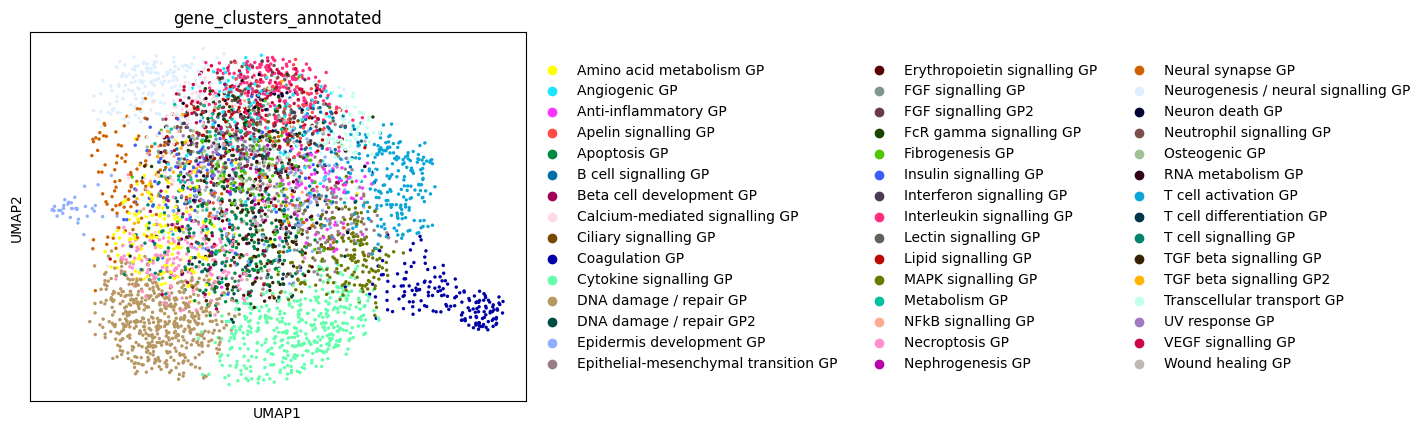

In [78]:
sc.pl.umap(adata_gps,
           color='gene_clusters_annotated',
           show=False)

In [6]:
dataset = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_ordered.dataset')

In [7]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 88626282
})

In [9]:
n_nonzero_tokens = list(dataset['n_nonzero_tokens'])

In [10]:
n_nonzero_tokens[:1000]

[2071,
 526,
 1185,
 2245,
 1447,
 838,
 678,
 914,
 663,
 934,
 615,
 1409,
 1060,
 836,
 1392,
 1539,
 231,
 918,
 802,
 2330,
 1887,
 1845,
 620,
 1521,
 606,
 2419,
 1249,
 2709,
 1247,
 1365,
 2140,
 864,
 2681,
 2816,
 2816,
 775,
 1043,
 1029,
 470,
 975,
 973,
 876,
 714,
 1055,
 2816,
 1409,
 2740,
 2671,
 1392,
 2219,
 765,
 1075,
 505,
 819,
 2366,
 2247,
 1036,
 810,
 2816,
 356,
 1384,
 2816,
 2555,
 746,
 1916,
 824,
 2816,
 2351,
 608,
 2496,
 2152,
 972,
 1108,
 2816,
 806,
 902,
 1864,
 1100,
 1039,
 2750,
 1499,
 785,
 783,
 1454,
 2697,
 1232,
 2160,
 2803,
 1555,
 2816,
 1150,
 1570,
 1330,
 1618,
 724,
 2664,
 981,
 2776,
 2766,
 2753,
 2722,
 1237,
 2394,
 2816,
 2732,
 2240,
 2816,
 583,
 897,
 1085,
 791,
 2153,
 2816,
 1650,
 868,
 2256,
 920,
 749,
 2251,
 2465,
 1476,
 2285,
 2657,
 418,
 2268,
 665,
 708,
 2816,
 822,
 479,
 542,
 351,
 1650,
 2345,
 2767,
 836,
 1172,
 822,
 1475,
 2672,
 1370,
 894,
 2816,
 2489,
 2715,
 1666,
 1173,
 2816,
 566,
 2788,
 1

In [1]:
tokenizer_folder_path = '/nfs/team361/sb75/DATASETS/tokenizer'

In [2]:
tokenized_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10.dataset'

In [4]:
f'{tokenizer_folder_path}/{tokenized_data_folder_path.rsplit("/", 1)[-1].removesuffix(".dataset")}_precomputed_split_train.pkl'

'/nfs/team361/sb75/DATASETS/tokenizer/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_split_train.pkl'

In [6]:
import pickle
with open('/nfs/team361/sb75/DATASETS/tokenizer/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_split_train.pkl', "rb") as f: 
    train_idx = pickle.load(f)